In [7]:
# Libraries

%load_ext autoreload
%autoreload 2

import sys
import json
import math
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.tokenizer import CharTokenizer
from src.attention import MultiHeadSelfAttention

In [8]:
# Input Tokenizer

TOKENIZER_PATH = (
    PROJECT_ROOT / "data" / "processed" / "tokenizer.json"
)

with open(TOKENIZER_PATH, "r", encoding="utf-8") as file:
    tokenizer_state = json.load(file)

tokenizer = CharTokenizer.from_dict(tokenizer_state)

prompt = "ROMEO:\n"

token_ids = tokenizer.encode(prompt)

characters = list(prompt)

print("Prompt:", repr(prompt))
print("Characters:", characters)
print("Token IDs:", token_ids)
print("Vocabulary size:", tokenizer.vocab_size)

Prompt: 'ROMEO:\n'
Characters: ['R', 'O', 'M', 'E', 'O', ':', '\n']
Token IDs: [30, 27, 25, 17, 27, 10, 0]
Vocabulary size: 65


In [9]:
# Embedding

torch.manual_seed(42)

d_model = 128
n_heads = 4
head_size = d_model // n_heads

embedding = nn.Embedding(
    tokenizer.vocab_size,
    d_model
)

x = embedding(
    torch.tensor([token_ids], dtype=torch.long)
)

print("Input shape:", x.shape)
print("Embedding dimension:", d_model)
print("Number of heads:", n_heads)
print("Head dimension:", head_size)


Input shape: torch.Size([1, 7, 128])
Embedding dimension: 128
Number of heads: 4
Head dimension: 32


In [10]:
# Initialization

block_size = 64
dropout = 0.0

mha = MultiHeadSelfAttention(
    n_embd=d_model,
    n_heads=n_heads,
    block_size=block_size,
    dropout=dropout
)

mha.eval()

output, attention_maps = mha(
    x,
    return_attention=True
)

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Attention maps shape:", attention_maps.shape)

Input shape: torch.Size([1, 7, 128])
Output shape: torch.Size([1, 7, 128])
Attention maps shape: torch.Size([1, 4, 7, 7])


In [11]:
# Watching

head = mha.heads[0]

Q = head.query(x)
K = head.key(x)
V = head.value(x)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

print("Query:")
display(
    pd.DataFrame(
        Q[0].detach().numpy(),
        index=characters
    )
)

print("Key:")
display(
    pd.DataFrame(
        K[0].detach().numpy(),
        index=characters
    )
)

print("Value:")
display(
    pd.DataFrame(
        V[0].detach().numpy(),
        index=characters
    )
)

for i, head in enumerate(mha.heads):

    Q = head.query(x)
    K = head.key(x)
    V = head.value(x)

    print(f"Head {i + 1}")
    print("Q:", Q.shape)
    print("K:", K.shape)
    print("V:", V.shape)
    print("-" * 40)

Q shape: torch.Size([1, 7, 32])
K shape: torch.Size([1, 7, 32])
V shape: torch.Size([1, 7, 32])
Query:


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
R,-0.501100,-0.888978,-0.570591,-0.819473,-0.215181,0.295333,-0.453188,0.291332,-0.553597,0.397431,...,-0.457731,0.610198,0.525975,0.276412,0.071302,-0.310825,1.274529,0.031701,-0.378190,0.598805
O,0.780466,-0.633884,0.024484,-0.028975,-0.985490,-0.443703,-0.394547,0.413741,-0.092429,-0.207672,...,-0.230347,0.398171,0.746948,-0.219572,0.039242,-0.429361,0.253510,0.752411,0.318557,-0.288011
M,-0.046016,-0.361142,-0.492908,0.246911,-0.217574,0.392362,0.843948,0.394275,0.042160,0.017625,...,-0.638919,-0.773331,0.039089,-0.086571,-0.086887,0.267121,-0.133125,0.967231,0.606341,-0.781857
E,0.332399,-0.491754,0.004108,0.334520,-0.128221,0.735102,0.345820,0.061203,1.022203,0.926406,...,-0.078831,-0.280332,0.518266,-0.687505,-0.585849,-0.660350,-0.469619,0.274160,-0.597682,0.569870
O,0.780466,-0.633884,0.024484,-0.028975,-0.985490,-0.443703,-0.394547,0.413741,-0.092429,-0.207672,...,-0.230347,0.398171,0.746948,-0.219572,0.039242,-0.429361,0.253510,0.752411,0.318557,-0.288011
:,-0.123529,-0.666512,0.939458,-0.093745,-0.519939,-0.168912,0.577250,-0.328601,-0.488737,0.090624,...,0.029000,-0.439835,-0.075396,0.212352,-0.486785,-0.295167,0.016215,-0.932308,-0.171552,-0.516928
\n,-0.574430,0.505518,1.543539,-0.648466,-0.257561,-0.633710,-0.488595,-0.079624,-0.340841,-0.668791,...,1.001821,0.228056,-0.301261,-0.633972,-0.283328,0.346931,1.660044,-0.475499,-0.507412,0.564591


Key:


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
R,-0.015806,0.435225,-0.334857,0.159700,-0.802064,0.968598,-1.253527,0.154772,-0.381364,0.423589,...,0.034999,-0.515033,-0.006144,-1.115439,-0.845455,-0.440495,-0.295276,0.352383,-0.269816,0.336156
O,0.391202,0.323740,-0.973885,-0.089436,-0.167467,-0.491048,0.245519,-0.044022,-0.991502,-1.609993,...,-0.283335,0.901635,0.202918,0.393611,-0.226767,-0.529828,-0.252671,-0.729139,0.945720,0.801396
M,-0.676723,0.446360,-1.485412,-0.305800,-0.757548,-0.315144,0.121352,0.444424,0.267630,-0.364307,...,-0.068537,-0.379519,0.755361,-0.221306,0.472810,0.440146,0.015546,-0.982820,-0.159976,0.179414
E,-1.246594,0.868976,-0.733238,-0.226646,0.392259,-0.178577,0.553657,-0.833554,-0.241317,-0.469699,...,-0.127297,-0.369662,0.460736,-0.388496,-0.172557,-0.208219,-0.331244,-0.624281,-0.504202,0.509602
O,0.391202,0.323740,-0.973885,-0.089436,-0.167467,-0.491048,0.245519,-0.044022,-0.991502,-1.609993,...,-0.283335,0.901635,0.202918,0.393611,-0.226767,-0.529828,-0.252671,-0.729139,0.945720,0.801396
:,0.478461,-0.030466,-1.149521,0.446328,0.318163,0.129167,0.527820,0.087433,0.139871,0.559506,...,0.956187,0.300643,-1.340066,0.720336,0.744352,-0.188923,0.408617,-0.670133,0.604999,0.578260
\n,0.259286,-0.230853,-0.399246,-0.337510,-0.586230,-0.455988,1.334158,-1.107464,-0.472756,-0.451261,...,-0.049815,-0.008563,0.030445,-0.322219,0.162917,-0.204463,0.480150,-0.205456,0.472709,1.128985


Value:


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
R,-0.119227,0.314375,0.586924,0.176970,0.441432,-0.076840,0.010889,0.159394,1.039261,0.298371,...,-0.221693,0.231977,-0.127014,0.229172,0.122826,-0.048910,0.548459,0.749719,0.610858,-0.304186
O,-0.053651,0.431422,-0.410459,0.459016,0.017790,0.981800,0.529226,-1.010130,0.769914,0.591701,...,-0.610758,0.522609,-0.364675,0.359443,0.345389,0.899677,0.015710,0.154203,-0.329630,0.040499
M,-0.292624,-0.606606,-0.305422,-0.019509,-0.445394,-0.855943,0.683224,0.544197,0.034530,0.307737,...,-0.812300,0.313382,0.657323,0.288897,0.165336,-0.072705,-0.821075,-0.133044,-2.094155,-0.504299
E,-0.200572,-0.374723,-0.007317,0.090634,0.218759,0.776154,1.231844,-0.662351,-0.327698,0.489576,...,-0.237939,0.133173,0.345102,0.404550,0.913031,-0.160911,0.463653,0.151967,-1.026365,-0.092520
O,-0.053651,0.431422,-0.410459,0.459016,0.017790,0.981800,0.529226,-1.010130,0.769914,0.591701,...,-0.610758,0.522609,-0.364675,0.359443,0.345389,0.899677,0.015710,0.154203,-0.329630,0.040499
:,-0.234048,0.746998,0.623137,0.010463,0.719699,-0.337642,0.017063,0.124846,-0.880549,0.089998,...,0.074618,-0.361906,0.762832,-0.139749,-0.012945,-0.430355,0.218152,-0.332674,-0.015855,-0.505813
\n,-0.856066,0.156633,-0.252565,-0.355822,0.650680,0.604085,0.517368,-0.100370,0.850632,0.672755,...,-0.508065,0.143893,0.332410,0.724962,0.546923,1.043696,-1.273068,0.340423,-0.523369,-0.345092


Head 1
Q: torch.Size([1, 7, 32])
K: torch.Size([1, 7, 32])
V: torch.Size([1, 7, 32])
----------------------------------------
Head 2
Q: torch.Size([1, 7, 32])
K: torch.Size([1, 7, 32])
V: torch.Size([1, 7, 32])
----------------------------------------
Head 3
Q: torch.Size([1, 7, 32])
K: torch.Size([1, 7, 32])
V: torch.Size([1, 7, 32])
----------------------------------------
Head 4
Q: torch.Size([1, 7, 32])
K: torch.Size([1, 7, 32])
V: torch.Size([1, 7, 32])
----------------------------------------


In [12]:
# Single-head Attention

head = mha.heads[0]

Q = head.query(x)
K = head.key(x)
V = head.value(x)

# Calculate attention scores
scores = torch.matmul(
    Q,
    K.transpose(-2, -1)
)

scores = scores / math.sqrt(head_size)

# Apply causal mask
T = x.size(1)

mask = head.causal_mask[:T, :T]

masked_scores = scores.masked_fill(
    ~mask,
    torch.finfo(scores.dtype).min
)

# Calculate attention weights
weights = F.softmax(
    masked_scores,
    dim=-1
)

# Calculate weighted sum
head_output = torch.matmul(
    weights,
    V
)

print("Scores shape:", scores.shape)
print("Weights shape:", weights.shape)
print("Head output shape:", head_output.shape)

Scores shape: torch.Size([1, 7, 7])
Weights shape: torch.Size([1, 7, 7])
Head output shape: torch.Size([1, 7, 32])


In [13]:
# Display 

for i, head in enumerate(mha.heads):

    _, head_weights = head(x)

    print(f"Head {i + 1}")

    display(
        pd.DataFrame(
            head_weights[0].detach().numpy(),
            index=characters,
            columns=characters
        )
    )

Head 1


,R,O,M,E,O,:,\n
R,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
O,0.560435,0.439565,0.000000,0.000000,0.000000,0.000000,0.000000
M,0.389692,0.278662,0.331646,0.000000,0.000000,0.000000,0.000000
E,0.401929,0.126363,0.221127,0.250582,0.000000,0.000000,0.000000
O,0.273206,0.214283,0.177732,0.120495,0.214283,0.000000,0.000000
:,0.133534,0.167210,0.142591,0.191494,0.167210,0.197961,0.000000
\n,0.130652,0.132898,0.114686,0.157714,0.132898,0.109261,0.221892


Head 2


,R,O,M,E,O,:,\n
R,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
O,0.563715,0.436285,0.000000,0.000000,0.000000,0.000000,0.000000
M,0.296019,0.326231,0.377750,0.000000,0.000000,0.000000,0.000000
E,0.232934,0.259285,0.257219,0.250563,0.000000,0.000000,0.000000
O,0.227878,0.176366,0.234645,0.184745,0.176366,0.000000,0.000000
:,0.144717,0.219414,0.132653,0.132791,0.219414,0.151011,0.000000
\n,0.134581,0.163801,0.241857,0.099880,0.163801,0.100813,0.095266


Head 3


,R,O,M,E,O,:,\n
R,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
O,0.334625,0.665375,0.000000,0.000000,0.000000,0.000000,0.000000
M,0.204612,0.369394,0.425994,0.000000,0.000000,0.000000,0.000000
E,0.262238,0.283039,0.228748,0.225976,0.000000,0.000000,0.000000
O,0.118675,0.235977,0.197716,0.211656,0.235977,0.000000,0.000000
:,0.145427,0.178164,0.160551,0.168805,0.178164,0.168890,0.000000
\n,0.119581,0.175447,0.087668,0.196527,0.175447,0.080404,0.164925


Head 4


,R,O,M,E,O,:,\n
R,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
O,0.432405,0.567595,0.000000,0.000000,0.000000,0.000000,0.000000
M,0.225473,0.544319,0.230208,0.000000,0.000000,0.000000,0.000000
E,0.274022,0.199349,0.225436,0.301193,0.000000,0.000000,0.000000
O,0.206283,0.270776,0.143722,0.108443,0.270776,0.000000,0.000000
:,0.158131,0.203248,0.167166,0.161034,0.203248,0.107174,0.000000
\n,0.187010,0.143484,0.173274,0.094484,0.143484,0.095822,0.162441


C:\Users\ASUS\AppData\Local\Temp\ipykernel_14572\3443617384.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


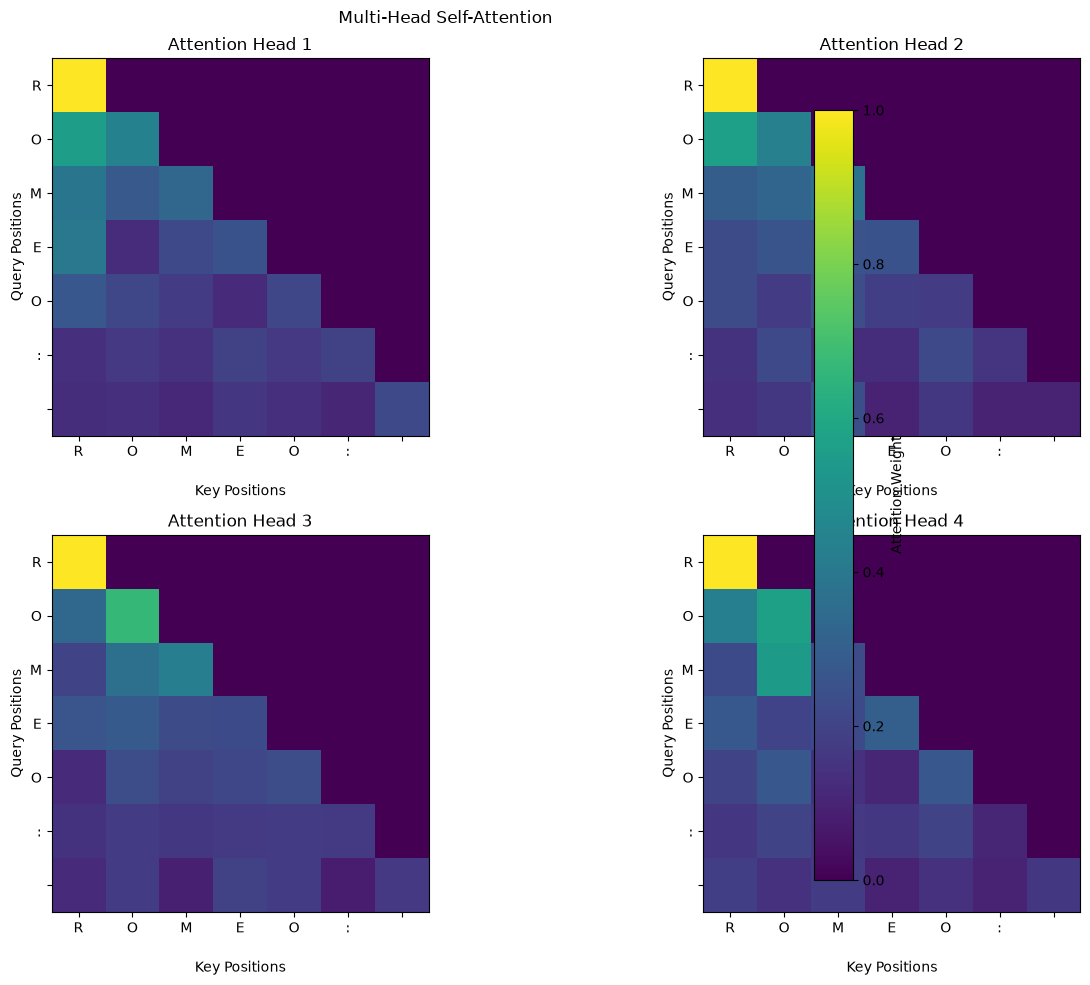

In [14]:
# Visualization

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 10)
)

for i, ax in enumerate(axes.flat):

    attention = attention_maps[0, i].detach().numpy()

    im = ax.imshow(
        attention,
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Attention Head {i + 1}")

    ax.set_xticks(range(len(characters)))
    ax.set_yticks(range(len(characters)))

    ax.set_xticklabels(characters)
    ax.set_yticklabels(characters)

    ax.set_xlabel("Key Positions")
    ax.set_ylabel("Query Positions")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="Attention Weight"
)

plt.suptitle("Multi-Head Self-Attention")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "multi_head_attention.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Concat

head_outputs = []

for head in mha.heads:

    head_output, _ = head(x)

    head_outputs.append(head_output)

concatenated = torch.cat(
    head_outputs,
    dim=-1
)

print("Head 1:", head_outputs[0].shape)
print("Head 2:", head_outputs[1].shape)
print("Head 3:", head_outputs[2].shape)
print("Head 4:", head_outputs[3].shape)

print("\nConcatenated shape:", concatenated.shape)

Head 1: torch.Size([1, 7, 32])
Head 2: torch.Size([1, 7, 32])
Head 3: torch.Size([1, 7, 32])
Head 4: torch.Size([1, 7, 32])

Concatenated shape: torch.Size([1, 7, 128])


In [16]:
# Output

projected = mha.proj(concatenated)

print("Before projection:", concatenated.shape)
print("After projection:", projected.shape)

# Before and After Projection

token_index = 0

before = concatenated[0, token_index].detach().numpy()

after = projected[0, token_index].detach().numpy()

comparison = pd.DataFrame({
    "Before Projection": before,
    "After Projection": after
})

display(comparison)

Before projection: torch.Size([1, 7, 128])
After projection: torch.Size([1, 7, 128])


,Before Projection,After Projection
0,-0.119227,-0.859945
1,0.314375,-0.031565
2,0.586924,-0.080485
3,0.176970,0.327990
4,0.441432,-0.147856
...,...,...
123,0.300922,-0.025300
124,-0.034253,0.573565
125,-0.159468,-0.247702
126,0.223442,-0.226509


In [17]:
# Vs src

output_src, attention_src = mha(
    x,
    return_attention=True
)

print(
    "Output matches:",
    torch.allclose(
        projected,
        output_src,
        atol=1e-6
    )
)

print(
    "Attention maps match:",
    torch.allclose(
        attention_maps,
        attention_src,
        atol=1e-6
    )
)

Output matches: True
Attention maps match: True


In [18]:
# Verify mask 

T = len(characters)

causal_mask = torch.tril(
    torch.ones(T, T, dtype=torch.bool)
)

for i in range(n_heads):

    weights = attention_maps[0, i]

    # Each row should sum to 1
    row_sums = weights.sum(dim=-1)

    # Future positions should receive zero attention
    future_weights = weights[~causal_mask]

    print(f"Head {i + 1}")

    print(
        "Rows sum to 1:",
        torch.allclose(
            row_sums,
            torch.ones_like(row_sums),
            atol=1e-6
        )
    )

    print(
        "Future weights are zero:",
        torch.allclose(
            future_weights,
            torch.zeros_like(future_weights),
            atol=1e-6
        )
    )

Head 1
Rows sum to 1: True
Future weights are zero: True
Head 2
Rows sum to 1: True
Future weights are zero: True
Head 3
Rows sum to 1: True
Future weights are zero: True
Head 4
Rows sum to 1: True
Future weights are zero: True


In [19]:
# Save

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save attention maps of each head
for i in range(n_heads):

    attention_df = pd.DataFrame(
        attention_maps[0, i].detach().numpy(),
        index=characters,
        columns=characters
    )

    attention_df.to_csv(
        RESULTS_DIR / f"attention_head_{i + 1}.csv"
    )

print("Attention results saved!")

Attention results saved!
